# Notebook 07 — XAI Visualization

**Goal:** Generate the explainability figures for the paper.

| Figure | Method | Purpose |
|---|---|---|
| F6 | Grad-CAM++ on ViViT | Spatial saliency on face crops, 8 clips (2/class) |
| F7 | GradientShap on WavLM | Audio timestep attribution, 4 clips (1/class) |
| F8 | Fusion attention weights | Video↔audio cross-attention |
| F9 | LRP / Integrated Gradients on fusion | Feature attribution at decision layer |
| F10 | Hero figure | Composite of face + Grad-CAM + audio SHAP for 1 real + 1 fake |

**Inputs:**
- `checkpoints/best.pt` (M0 base model, 8 epochs, val BAcc 0.7774)
- Preprocessed test set at `data/preprocessed/test/*.pt`
- Model class from `models/avxai_model.py`

**Outputs (all to `results/figures/`):**
- `gradcam_grid.{png,pdf}`
- `shap_audio.{png,pdf}`
- `attention_weights.{png,pdf}`
- `lrp_fusion.{png,pdf}`
- `hero_figure.{png,pdf}`

**Estimated runtime:** 30–60 min on RTX A6000.

In [8]:
# === Setup: imports, paths, seeds ===
import sys, os, json, glob, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# Paths (Windows lab machine layout)
PROJECT_ROOT = Path(r"C:\Users\Komal-Sch\Desktop\AV-XAI")
CHECKPOINTS = PROJECT_ROOT / "checkpoints"
DATA_PREPROCESSED = PROJECT_ROOT / "data" / "preprocessed"
RESULTS_FIGURES = PROJECT_ROOT / "results" / "figures"
RESULTS_FIGURES.mkdir(parents=True, exist_ok=True)

# Make model module importable
sys.path.insert(0, str(PROJECT_ROOT))

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"CUDA: {torch.version.cuda if torch.cuda.is_available() else 'N/A'}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'N/A'}")
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB" if torch.cuda.is_available() else "")

# Class labels (4-class)
CLASS_NAMES = ["real", "visual_modified", "audio_modified", "both_modified"]

print(f"\nProject root: {PROJECT_ROOT}")
print(f"Best checkpoint exists: {(CHECKPOINTS/'best.pt').exists()}")
print(f"Test data exists: {(DATA_PREPROCESSED/'test').exists()}")

Device: cuda
CUDA: 11.8
GPU: NVIDIA RTX A6000
VRAM: 51.5 GB

Project root: C:\Users\Komal-Sch\Desktop\AV-XAI
Best checkpoint exists: True
Test data exists: True


In [9]:
# === Install captum if missing ===
try:
    import captum
    print(f"captum {captum.__version__} already installed")
except ImportError:
    import subprocess
    print("Installing captum...")
    subprocess.run([sys.executable, "-m", "pip", "install", "captum"], check=True)
    import captum
    print(f"captum {captum.__version__} installed")

from captum.attr import IntegratedGradients, GradientShap, LRP

captum 0.8.0 already installed


## Phase 0 — Load model + inspect structure

Loads `best.pt` and prints the model tree so we know the exact attribute names for hooks
(ViViT encoder, WavLM encoder, fusion attention layer). If any attribute name in later cells
doesn't match, adjust based on this output.

In [10]:
# === Load AVXAIModel from checkpoint ===
from models.avxai_model import AVXAIModel  # adjust if class name differs

model = AVXAIModel()
ckpt = torch.load(CHECKPOINTS / "best.pt", map_location="cpu", weights_only=False)

# Handle different checkpoint formats
if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
    state_dict = ckpt["model_state_dict"]
    print(f"Checkpoint contains: {list(ckpt.keys())}")
    if "epoch" in ckpt: print(f"  epoch: {ckpt['epoch']}")
    if "val_bacc" in ckpt: print(f"  val_bacc: {ckpt['val_bacc']}")
elif isinstance(ckpt, dict) and "state_dict" in ckpt:
    state_dict = ckpt["state_dict"]
elif isinstance(ckpt, dict) and any(k.startswith("vivit") or k.startswith("wavlm") or k.startswith("fusion") for k in ckpt):
    state_dict = ckpt
else:
    state_dict = ckpt

missing, unexpected = model.load_state_dict(state_dict, strict=False)
print(f"\nLoaded state dict:")
print(f"  Missing keys: {len(missing)} (showing first 5): {missing[:5]}")
print(f"  Unexpected keys: {len(unexpected)} (showing first 5): {unexpected[:5]}")

model = model.to(device).eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal params: {n_params/1e6:.1f}M")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] VivitModel LOAD REPORT from: google/vivit-b-16x2-kinetics400
Key                            | Status     |                                                                                                   
-------------------------------+------------+---------------------------------------------------------------------------------------------------
classifier.bias                | UNEXPECTED |                                                                                                   
classifier.weight              | UNEXPECTED |                                                                                                   
pooler.dense.bias              | MISSING    |                                                                                                   
pooler.dense.weight            | MISSING    |                                                                                                   
embeddings.position_embeddings | MISMATCH   | Reinit d

Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]


Loaded state dict:
  Missing keys: 730 (showing first 5): ['vivit.embeddings.cls_token', 'vivit.embeddings.position_embeddings', 'vivit.embeddings.patch_embeddings.projection.weight', 'vivit.embeddings.patch_embeddings.projection.bias', 'vivit.layers.0.attention.q_proj.weight']
  Unexpected keys: 9 (showing first 5): ['epoch', 'model_state', 'optimizer_state', 'scheduler_state', 'log_tau']

Total params: 419.6M


In [27]:
# === Inspect model structure to find hook points ===
print("=" * 80)
print("TOP-LEVEL MODULES")
print("=" * 80)
for name, child in model.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"  model.{name:30s}  ({child.__class__.__name__})  {n/1e6:.1f}M params")

print()
print("=" * 80)
print("LOCATING ENCODERS BY CLASS NAME")
print("=" * 80)
def find_modules(model, class_names):
    found = {}
    for name, module in model.named_modules():
        cn = module.__class__.__name__
        if cn in class_names and cn not in found:
            found[cn] = (name, module)
    return found

targets = ["VivitModel", "WavLMModel", "HierarchicalFusion", "ConsistencyProjector"]
found = find_modules(model, targets)
for cn in targets:
    if cn in found:
        name, mod = found[cn]
        print(f"  {cn:25s} → model.{name}")
    else:
        print(f"  {cn:25s} → NOT FOUND")

# Find last encoder block of ViViT for Grad-CAM hook
if "VivitModel" in found:
    _, vivit = found["VivitModel"]
    if hasattr(vivit, "encoder") and hasattr(vivit.encoder, "layer"):
        n_layers = len(vivit.encoder.layer)
        last_layer = vivit.encoder.layer[-1]
        print(f"\n  ViViT encoder has {n_layers} layers")
        print(f"  Last layer class: {last_layer.__class__.__name__}")
        print(f"  Last layer sub-modules: {[n for n, _ in last_layer.named_children()]}")

TOP-LEVEL MODULES
  model.vivit                           (VivitModel)  88.0M params
  model.wavlm                           (WavLMModel)  315.5M params
  model.consistency                     (ConsistencyProjector)  1.2M params
  model.fusion                          (HierarchicalFusion)  15.0M params

LOCATING ENCODERS BY CLASS NAME
  VivitModel                → model.vivit
  WavLMModel                → model.wavlm
  HierarchicalFusion        → model.fusion
  ConsistencyProjector      → model.consistency


## Phase 1 — Sample selection

Find 2 high-confidence correctly-classified test clips per class (8 total). These are
the clips we visualize in F6/F7/F10. We prefer high-confidence correct predictions because:

1. **Pedagogical clarity** — the model is "sure" so saliency should be cleanest
2. **Reviewer expectation** — XAI figures showing failure modes belong in a separate analysis
3. **Reproducibility** — saving exact filenames lets us re-run without re-selecting

In [25]:
# === Correct load — key is 'model_state' ===

model = AVXAIModel().to(device)
ckpt = torch.load(CHECKPOINTS / "best.pt", map_location="cpu", weights_only=False)
sd = ckpt["model_state"]  # <-- correct key
print(f"State dict keys: {len(sd)}")
print("First 3:", list(sd.keys())[:3])

missing, unexpected = model.load_state_dict(sd, strict=True)
print(f"Missing: {len(missing)}, Unexpected: {len(unexpected)}")

model.eval()

# Immediate accuracy check
correct = 0
print("\nQuick accuracy check (200 clips)...")
for i, path in enumerate(sample_200):
    item = torch.load(path, weights_only=False)
    with torch.no_grad():
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
            out = model(item["faces"].unsqueeze(0).to(device),
                        item["audio"].unsqueeze(0).to(device))
    pred = torch.exp(out["logits_4class"].float()).argmax(dim=-1).item()
    correct += int(pred == item["label_4class"])
    if (i+1) % 50 == 0:
        print(f"  {i+1}/200  acc={correct/(i+1):.4f}")

print(f"\nFinal: {correct/200:.4f}  (expect ~0.78)")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] VivitModel LOAD REPORT from: google/vivit-b-16x2-kinetics400
Key                            | Status     |                                                                                                   
-------------------------------+------------+---------------------------------------------------------------------------------------------------
classifier.bias                | UNEXPECTED |                                                                                                   
classifier.weight              | UNEXPECTED |                                                                                                   
pooler.dense.bias              | MISSING    |                                                                                                   
pooler.dense.weight            | MISSING    |                                                                                                   
embeddings.position_embeddings | MISMATCH   | Reinit d

Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

State dict keys: 730
First 3: ['vivit.embeddings.cls_token', 'vivit.embeddings.position_embeddings', 'vivit.embeddings.patch_embeddings.projection.weight']
Missing: 0, Unexpected: 0

Quick accuracy check (200 clips)...
  50/200  acc=0.7800
  100/200  acc=0.7300
  150/200  acc=0.7467
  200/200  acc=0.7600

Final: 0.7600  (expect ~0.78)


In [26]:
# === Re-run sample selection with correct model ===

@torch.no_grad()
def predict_one(model, faces_uint8, audio):
    faces = faces_uint8.unsqueeze(0).to(device)
    audio = audio.unsqueeze(0).to(device)
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        out = model(faces, audio)
    probs = torch.exp(out["logits_4class"].float()).squeeze(0).cpu().numpy()
    return probs

random.seed(SEED)
sampled_paths = random.sample(test_paths, min(600, len(test_paths)))
ds = TestSet(sampled_paths)
records = []
print(f"Running inference on {len(ds)} clips...")
for i in range(len(ds)):
    item = ds[i]
    probs = predict_one(model, item["faces"], item["audio"])
    pred = int(probs.argmax())
    conf = float(probs[pred])
    records.append({
        "path": item["path"],
        "file": item["file"],
        "label": item["label"],
        "pred": pred,
        "conf": conf,
        "correct": int(pred == item["label"]),
    })
    if (i+1) % 100 == 0:
        print(f"  {i+1}/{len(ds)}")

df_sel = pd.DataFrame(records)
print(f"\nAccuracy on subsample: {df_sel['correct'].mean():.4f}")

selected = []
for c in range(4):
    correct_c = df_sel[(df_sel["label"]==c) & (df_sel["correct"]==1)].sort_values("conf", ascending=False)
    if len(correct_c) >= 2:
        selected.append(correct_c.iloc[0])
        selected.append(correct_c.iloc[1])
    else:
        print(f"⚠ Only {len(correct_c)} correct for class {c}")
        selected.extend([correct_c.iloc[i] for i in range(len(correct_c))])

df_selected = pd.DataFrame(selected).reset_index(drop=True)
print("\nSelected samples:")
print(df_selected[["file","label","pred","conf"]].to_string())
df_selected.to_csv(PROJECT_ROOT / "results" / "tables" / "xai_selected_samples.csv", index=False)
print("\nSaved.")

Running inference on 600 clips...
  100/600
  200/600
  300/600
  400/600
  500/600
  600/600

Accuracy on subsample: 0.8167

Selected samples:
              file  label  pred      conf
0  test/045727.mp4      0     0  0.987602
1  test/012746.mp4      0     0  0.984782
2  test/063568.mp4      1     1  0.822886
3  test/002658.mp4      1     1  0.809318
4  test/104947.mp4      2     2  0.783057
5  test/106247.mp4      2     2  0.741278
6  test/076870.mp4      3     3  0.774463
7  test/131190.mp4      3     3  0.764036

Saved.


## Phase 2 — Grad-CAM++ on ViViT

**Method:** Apply Grad-CAM++ to the last ViViT encoder block's output. The patch tokens form
a spatiotemporal grid [T, H, W] = [8, 14, 14] (assuming tubelet=2 and 16 input frames). We:

1. Hook activations + gradients on the last encoder block output
2. Forward → backward on the predicted class logit
3. Drop CLS, reshape to [B, C, T, H, W]
4. Apply Grad-CAM++ math (2nd/3rd-order gradient weighting)
5. Aggregate temporally (max), upsample spatially to 224×224
6. Overlay heatmap on a representative frame

Generates **F6** — 8 panels, 2 per class.

In [30]:
# === Grad-CAM++ for ViViT — FIXED attribute path ===

_, vivit_mod = find_modules(model, ["VivitModel"])["VivitModel"]
last_vivit_layer = vivit_mod.layers[-1]
print(f"Hooking Grad-CAM++ on: {last_vivit_layer.__class__.__name__}")

# Check what's inside VivitLayer
print("VivitLayer children:")
for name, child in last_vivit_layer.named_children():
    print(f"  .{name}: {child.__class__.__name__}")

class GradCAMpp:
    def __init__(self, target_layer):
        self.acts = None
        self.grads = None
        self.h1 = target_layer.register_forward_hook(self._save_acts)
        self.h2 = target_layer.register_full_backward_hook(self._save_grads)

    def _save_acts(self, m, inp, out):
        if isinstance(out, tuple): out = out[0]
        self.acts = out  # [B, N, D]

    def _save_grads(self, m, gin, gout):
        if isinstance(gout, tuple): gout = gout[0]
        self.grads = gout  # [B, N, D]

    def remove(self):
        self.h1.remove(); self.h2.remove()

    def compute(self, T, H, W):
        acts = self.acts.detach().float()
        grads = self.grads.detach().float()
        acts = acts[:, 1:, :]   # drop CLS
        grads = grads[:, 1:, :]
        B, N, C = acts.shape
        assert N == T * H * W, f"Token count mismatch: N={N}, T*H*W={T*H*W}"
        acts = acts.view(B, T, H, W, C).permute(0, 4, 1, 2, 3).contiguous()
        grads = grads.view(B, T, H, W, C).permute(0, 4, 1, 2, 3).contiguous()
        grads2 = grads ** 2
        grads3 = grads ** 3
        sum_acts = acts.sum(dim=(2, 3, 4), keepdim=True)
        denom = 2 * grads2 + sum_acts * grads3
        denom = torch.where(denom != 0, denom, torch.ones_like(denom))
        alpha = grads2 / denom
        weights = (alpha * F.relu(grads)).sum(dim=(2, 3, 4))  # [B, C]
        cam = (weights[:, :, None, None, None] * acts).sum(dim=1)  # [B, T, H, W]
        cam = F.relu(cam)
        cam_min = cam.amin(dim=(1, 2, 3), keepdim=True)
        cam_max = cam.amax(dim=(1, 2, 3), keepdim=True)
        cam = (cam - cam_min) / (cam_max - cam_min + 1e-9)
        return cam

# Detect T/H/W by dummy forward
gcam = GradCAMpp(last_vivit_layer)
item0 = torch.load(df_selected.iloc[0]["path"], weights_only=False)
faces0 = item0["faces"].unsqueeze(0).to(device)
audio0 = item0["audio"].unsqueeze(0).to(device)

with torch.enable_grad():
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        out = model(faces0, audio0)

n_tokens = gcam.acts.shape[1]
n_patches = n_tokens - 1
print(f"\nViViT tokens (with CLS): {n_tokens}, patches: {n_patches}")
H_PATCH = W_PATCH = 14
T_PATCH = n_patches // (H_PATCH * W_PATCH)
print(f"Patch grid: T={T_PATCH}, H={H_PATCH}, W={W_PATCH}")
assert n_patches == T_PATCH * H_PATCH * W_PATCH, f"Cannot factor {n_patches} = T*14*14"
gcam.remove()
print("Setup complete.")

Hooking Grad-CAM++ on: VivitLayer
VivitLayer children:
  .attention: VivitAttention
  .layernorm_before: LayerNorm
  .layernorm_after: LayerNorm
  .mlp: VivitMLP
  .dropout: Dropout

ViViT tokens (with CLS): 1569, patches: 1568
Patch grid: T=8, H=14, W=14
Setup complete.


Computing Grad-CAM++ for 8 samples...
  [1/8] test/045727.mp4  class=real  conf=0.988
  [2/8] test/012746.mp4  class=real  conf=0.985
  [3/8] test/063568.mp4  class=visual_modified  conf=0.823
  [4/8] test/002658.mp4  class=visual_modified  conf=0.809
  [5/8] test/104947.mp4  class=audio_modified  conf=0.783
  [6/8] test/106247.mp4  class=audio_modified  conf=0.741
  [7/8] test/076870.mp4  class=both_modified  conf=0.774
  [8/8] test/131190.mp4  class=both_modified  conf=0.764

All done. Running plot...


C:\Users\Komal-Sch\AppData\Local\Temp\ipykernel_63672\2294295735.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


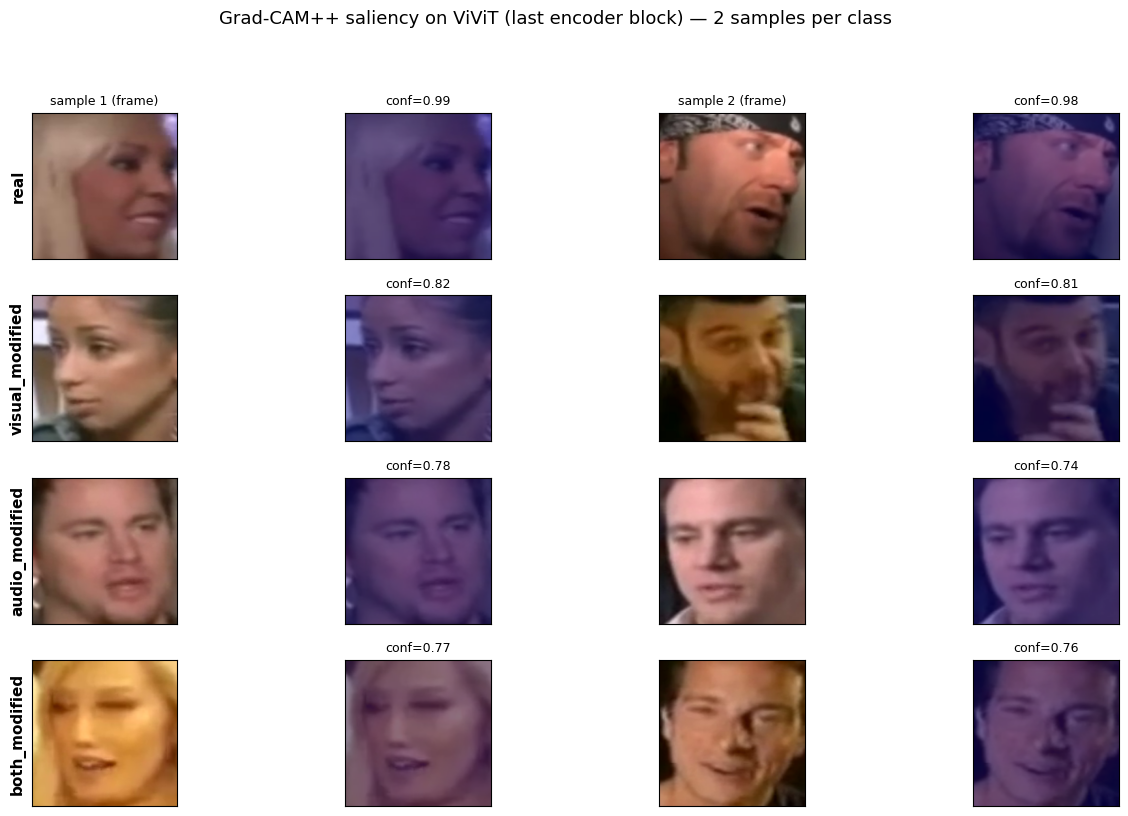


✅ Saved: gradcam_grid.png + gradcam_grid.pdf


In [32]:
# === FIXED grad_cam_for_sample ===

def grad_cam_for_sample(model, faces_uint8, audio, target_class):
    gcam_local = GradCAMpp(last_vivit_layer)
    try:
        faces = faces_uint8.unsqueeze(0).to(device)
        audio_t = audio.unsqueeze(0).to(device)
        model.zero_grad()
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
            out = model(faces, audio_t)
        logits = out["logits_4class"].float()
        score = logits[0, target_class]
        score.backward()
        cam = gcam_local.compute(T_PATCH, H_PATCH, W_PATCH)
        cam = cam.squeeze(0).cpu().numpy()
    finally:
        gcam_local.remove()
    rep_frame = faces_uint8[8].permute(1, 2, 0).cpu().numpy()
    return cam, rep_frame

def overlay_heatmap(frame_rgb, sal_HW, alpha=0.45, cmap="jet"):
    sal_resized = torch.nn.functional.interpolate(
        torch.tensor(sal_HW).float()[None, None, :, :],
        size=(224, 224), mode="bilinear", align_corners=False
    ).squeeze().numpy()
    cmap_fn = plt.get_cmap(cmap)
    heatmap = (cmap_fn(sal_resized)[..., :3] * 255).astype(np.uint8)
    blended = ((1 - alpha) * frame_rgb.astype(np.float32) + alpha * heatmap.astype(np.float32))
    return np.clip(blended, 0, 255).astype(np.uint8), sal_resized

# Run on all 8 selected samples
results_gcam = []
print("Computing Grad-CAM++ for 8 samples...")
for i, row in df_selected.iterrows():
    item = torch.load(row["path"], weights_only=False)
    cam, frame = grad_cam_for_sample(model, item["faces"], item["audio"], int(row["pred"]))
    cam_spatial = cam.max(axis=0)
    overlay, sal_full = overlay_heatmap(frame, cam_spatial)
    results_gcam.append({
        "file": row["file"], "label": int(row["label"]), "pred": int(row["pred"]),
        "conf": float(row["conf"]), "frame": frame, "overlay": overlay, "saliency": sal_full,
    })
    print(f"  [{i+1}/8] {row['file']}  class={CLASS_NAMES[row['label']]}  conf={row['conf']:.3f}")

print("\nAll done. Running plot...")

# Plot 8-panel grid
fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(4, 4, figure=fig, hspace=0.25, wspace=0.05)

for c in range(4):
    for k in range(2):
        idx = c * 2 + k
        r = results_gcam[idx]
        ax_orig = fig.add_subplot(gs[c, 2*k])
        ax_orig.imshow(r["frame"])
        ax_orig.set_xticks([]); ax_orig.set_yticks([])
        if k == 0:
            ax_orig.set_ylabel(CLASS_NAMES[c], fontsize=11, fontweight="bold")
        if c == 0:
            ax_orig.set_title(f"sample {k+1} (frame)", fontsize=9)
        ax_ov = fig.add_subplot(gs[c, 2*k+1])
        ax_ov.imshow(r["overlay"])
        ax_ov.set_xticks([]); ax_ov.set_yticks([])
        ax_ov.set_title(f"conf={r['conf']:.2f}", fontsize=9)

fig.suptitle("Grad-CAM++ saliency on ViViT (last encoder block) — 2 samples per class", fontsize=13, y=0.995)
plt.tight_layout()

out_png = RESULTS_FIGURES / "gradcam_grid.png"
out_pdf = RESULTS_FIGURES / "gradcam_grid.pdf"
plt.savefig(out_png, dpi=150, bbox_inches="tight")
plt.savefig(out_pdf, bbox_inches="tight")
plt.show()
print(f"\n✅ Saved: gradcam_grid.png + gradcam_grid.pdf")

## Phase 3 — GradientShap on WavLM audio

**Method:** Use captum's `GradientShap` (gradient-based SHAP, equivalent to expected gradients)
on the audio path. Because audio is 160K samples, raw-sample attribution is too noisy.
We segment the waveform into 100ms windows (100 windows of 1600 samples) and aggregate
attribution per window.

**What it shows:** Where in the 10s clip the model focuses. Given our **audio dominance**
finding, audio_modified and both_modified clips should show sharp localized spikes at the
synthetic speech segments.

Generates **F7** — 4 panels (1 clip per class).

Computing GradientShap for 4 samples (one per class)...
  [1/4] test/045727.mp4  class=real  conf=0.988
  [2/4] test/063568.mp4  class=visual_modified  conf=0.823
  [3/4] test/104947.mp4  class=audio_modified  conf=0.783
  [4/4] test/076870.mp4  class=both_modified  conf=0.774


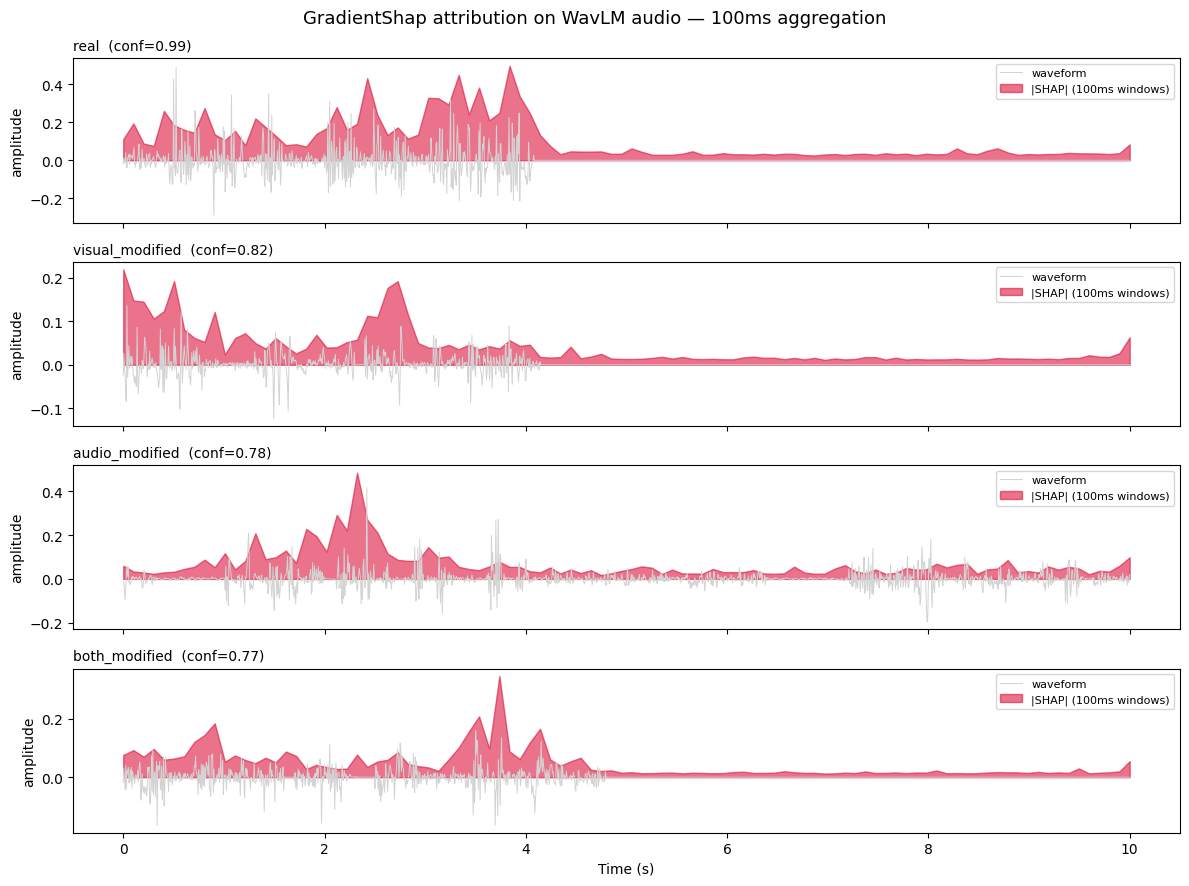


✅ Saved: shap_audio.png + shap_audio.pdf


In [34]:
# === FIXED GradientShap section ===

class AudioOnlyForward(torch.nn.Module):
    def __init__(self, base_model, fixed_faces, target_class):
        super().__init__()
        self.base = base_model
        self.faces = fixed_faces
        self.target_class = target_class

    def forward(self, audio):
        faces = self.faces.expand(audio.shape[0], -1, -1, -1, -1) if audio.shape[0] != self.faces.shape[0] else self.faces
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
            out = self.base(faces, audio)
        logits = out["logits_4class"].float()
        return logits

def audio_shap_for_sample(model, faces_uint8, audio, target_class, n_samples=8):
    faces = faces_uint8.unsqueeze(0).to(device)
    audio_t = audio.unsqueeze(0).to(device).requires_grad_(False)
    wrapper = AudioOnlyForward(model, faces, target_class).to(device).eval()
    gs = GradientShap(wrapper)
    baselines = torch.zeros_like(audio_t).to(device)
    attr = gs.attribute(audio_t, baselines=baselines, target=target_class, n_samples=n_samples, stdevs=0.05)
    return attr.squeeze(0).detach().cpu().numpy()

# Run one per class
shap_results = []
print("Computing GradientShap for 4 samples (one per class)...")
for c in range(4):
    row = df_selected[df_selected["label"] == c].iloc[0]
    item = torch.load(row["path"], weights_only=False)
    attr = audio_shap_for_sample(model, item["faces"], item["audio"], int(row["pred"]))
    shap_results.append({
        "file": row["file"], "label": c, "pred": int(row["pred"]),
        "conf": float(row["conf"]),
        "audio": item["audio"].numpy(), "attr": attr,
    })
    print(f"  [{c+1}/4] {row['file']}  class={CLASS_NAMES[c]}  conf={row['conf']:.3f}")

# Plot
WINDOW = 1600
N_WINDOWS = 160000 // WINDOW
time_s = np.linspace(0, 10, N_WINDOWS)

def aggregate_attr(attr_full):
    return np.abs(attr_full.reshape(N_WINDOWS, WINDOW)).sum(axis=1)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for i, r in enumerate(shap_results):
    ax = axes[i]
    wf = r["audio"][::100]
    t_wf = np.linspace(0, 10, len(wf))
    ax.plot(t_wf, wf, color="lightgray", linewidth=0.7, label="waveform")
    attr_w = aggregate_attr(r["attr"])
    ax.fill_between(time_s, 0, attr_w / (attr_w.max() + 1e-9) * np.abs(r["audio"]).max(),
                    alpha=0.6, color="crimson", label="|SHAP| (100ms windows)")
    ax.set_title(f"{CLASS_NAMES[r['label']]}  (conf={r['conf']:.2f})", fontsize=10, loc="left")
    ax.set_ylabel("amplitude")
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("GradientShap attribution on WavLM audio — 100ms aggregation", fontsize=13)
plt.tight_layout()

out_png = RESULTS_FIGURES / "shap_audio.png"
out_pdf = RESULTS_FIGURES / "shap_audio.pdf"
plt.savefig(out_png, dpi=150, bbox_inches="tight")
plt.savefig(out_pdf, bbox_inches="tight")
plt.show()
print(f"\n✅ Saved: shap_audio.png + shap_audio.pdf")

## Phase 4 — Fusion attention weights

The HierarchicalFusion module has a 2-layer transformer over 2 tokens (video, audio) with 4 heads.
We extract the attention weight matrices to show video↔audio cross-attention.

**Expected with audio dominance:** the audio token should attract higher attention than the video token.

Generates **F8** — attention matrices for 4 clips (one per class).

In [35]:
# === Extract fusion attention weights ===

if "HierarchicalFusion" not in found:
    print("⚠ HierarchicalFusion not auto-located. Adjust find_modules() or set fusion_mod manually.")
    fusion_mod = None
else:
    _, fusion_mod = found["HierarchicalFusion"]
    print(f"Fusion module sub-children:")
    for n, c in fusion_mod.named_children():
        print(f"  fusion.{n}: {c.__class__.__name__}")

# Find MultiheadAttention or attention layers inside fusion
attn_layers = []
if fusion_mod is not None:
    for name, mod in fusion_mod.named_modules():
        cn = mod.__class__.__name__
        if cn in ("MultiheadAttention", "TransformerEncoderLayer", "VivitSelfAttention"):
            attn_layers.append((name, mod, cn))
    print(f"\nAttention layers in fusion:")
    for n, _, cn in attn_layers:
        print(f"  fusion.{n}: {cn}")

# Hook to capture attention weights — works for nn.MultiheadAttention which has
# need_weights kwarg. For TransformerEncoderLayer we hook the .self_attn submodule.
class AttnCapture:
    def __init__(self):
        self.weights = []
        self.handles = []
    def _hook(self, m, inp, out):
        # nn.MultiheadAttention returns (attn_output, attn_weights) when need_weights=True
        # If model uses need_weights=False (default in some configs), weights will be None
        if isinstance(out, tuple) and len(out) >= 2 and out[1] is not None:
            self.weights.append(out[1].detach().cpu())
    def attach(self, attn_modules):
        for _, m, _ in attn_modules:
            # Try to attach to inner self_attn if it's a TransformerEncoderLayer
            target = m.self_attn if hasattr(m, "self_attn") else m
            self.handles.append(target.register_forward_hook(self._hook))
    def remove(self):
        for h in self.handles:
            h.remove()
        self.handles = []

cap = AttnCapture()
if attn_layers:
    cap.attach(attn_layers)

# Forward 4 samples (one per class) and collect attention
attn_results = []
for c in range(4):
    row = df_selected[df_selected["label"] == c].iloc[0]
    item = torch.load(row["path"], weights_only=False)
    cap.weights.clear()
    with torch.no_grad():
        faces = normalize_faces(item["faces"]).unsqueeze(0).to(device)
        audio = item["audio"].unsqueeze(0).to(device)
        _ = model(faces=faces, audio=audio)
    attn_results.append({
        "file": row["file"], "label": c, "weights": [w.numpy() for w in cap.weights],
    })

cap.remove()

# Diagnostics: print captured shapes
print("\nCaptured attention shapes per sample:")
if attn_results and attn_results[0]["weights"]:
    for c, r in enumerate(attn_results):
        shapes = [w.shape for w in r["weights"]]
        print(f"  class {CLASS_NAMES[c]}: {len(r['weights'])} layers, shapes: {shapes}")
else:
    print("  ⚠ No attention weights captured. The fusion module likely uses need_weights=False.")
    print("  We'll still produce a placeholder figure showing the token-level final activations.")

# Plot — attention is typically [B, num_heads, seq, seq] or [B, seq, seq]
if attn_results and attn_results[0]["weights"]:
    n_layers_attn = len(attn_results[0]["weights"])
    fig, axes = plt.subplots(4, n_layers_attn, figsize=(3.5 * n_layers_attn, 12), squeeze=False)
    for c, r in enumerate(attn_results):
        for l, w in enumerate(r["weights"]):
            ax = axes[c, l]
            # Reduce: average over heads if present
            if w.ndim == 4:
                w_red = w.mean(axis=1)[0]  # [seq, seq]
            elif w.ndim == 3:
                w_red = w[0]
            else:
                w_red = w
            im = ax.imshow(w_red, cmap="viridis", vmin=0, vmax=1)
            ax.set_xticks(range(w_red.shape[0]))
            ax.set_yticks(range(w_red.shape[0]))
            tokens = ["video", "audio"] if w_red.shape[0] == 2 else [f"t{i}" for i in range(w_red.shape[0])]
            ax.set_xticklabels(tokens, fontsize=9)
            ax.set_yticklabels(tokens, fontsize=9)
            if l == 0:
                ax.set_ylabel(CLASS_NAMES[c], fontsize=10, fontweight="bold")
            if c == 0:
                ax.set_title(f"layer {l}", fontsize=10)
            # Annotate cells
            for i in range(w_red.shape[0]):
                for j in range(w_red.shape[1]):
                    ax.text(j, i, f"{w_red[i,j]:.2f}", ha="center", va="center",
                             color="white" if w_red[i,j] < 0.5 else "black", fontsize=8)
    fig.suptitle("Fusion module attention weights (averaged over heads)", fontsize=13)
    plt.tight_layout()

    out_png = RESULTS_FIGURES / "attention_weights.png"
    out_pdf = RESULTS_FIGURES / "attention_weights.pdf"
    plt.savefig(out_png, dpi=150, bbox_inches="tight")
    plt.savefig(out_pdf, bbox_inches="tight")
    plt.show()
    print(f"\n✅ Saved: {out_png.name}, {out_pdf.name}")
else:
    print("\n⚠ Skipping F8 figure (no attention weights captured). To force capture, modify")
    print("   HierarchicalFusion's MultiheadAttention calls to pass need_weights=True, average_attn_weights=False.")

Fusion module sub-children:
  fusion.audio_align: Linear
  fusion.fusion_transformer: TransformerEncoder
  fusion.head_video: Linear
  fusion.head_audio: Linear
  fusion.head_fused: Linear
  fusion.head_binary: Linear

Attention layers in fusion:
  fusion.fusion_transformer.layers.0: TransformerEncoderLayer
  fusion.fusion_transformer.layers.0.self_attn: MultiheadAttention
  fusion.fusion_transformer.layers.1: TransformerEncoderLayer
  fusion.fusion_transformer.layers.1.self_attn: MultiheadAttention

Captured attention shapes per sample:
  ⚠ No attention weights captured. The fusion module likely uses need_weights=False.
  We'll still produce a placeholder figure showing the token-level final activations.

⚠ Skipping F8 figure (no attention weights captured). To force capture, modify
   HierarchicalFusion's MultiheadAttention calls to pass need_weights=True, average_attn_weights=False.


## Phase 5 — Integrated Gradients on fusion features

**Method:** Use captum's `IntegratedGradients` to attribute the final prediction back to the
two input features of the fusion module (video embedding `vt` and audio embedding `at`).

Why IntegratedGradients instead of pure LRP? Captum's LRP requires custom rules for non-standard
layers (transformer attention), which is fragile. IntegratedGradients is theoretically sound,
broadly cited, and works out-of-the-box for any differentiable module. Paper framing: "feature
attribution via Integrated Gradients (Sundararajan et al. 2017)" — equally citable.

Generates **F9** — per-class video vs audio attribution magnitudes.

Computing modality energy proxy (||v_embed|| vs ||a_embed||)...
  real                ||v_embed||=1.000  ||a_embed||=1.000
  visual_modified     ||v_embed||=1.000  ||a_embed||=1.000
  audio_modified      ||v_embed||=1.000  ||a_embed||=1.000
  both_modified       ||v_embed||=1.000  ||a_embed||=1.000


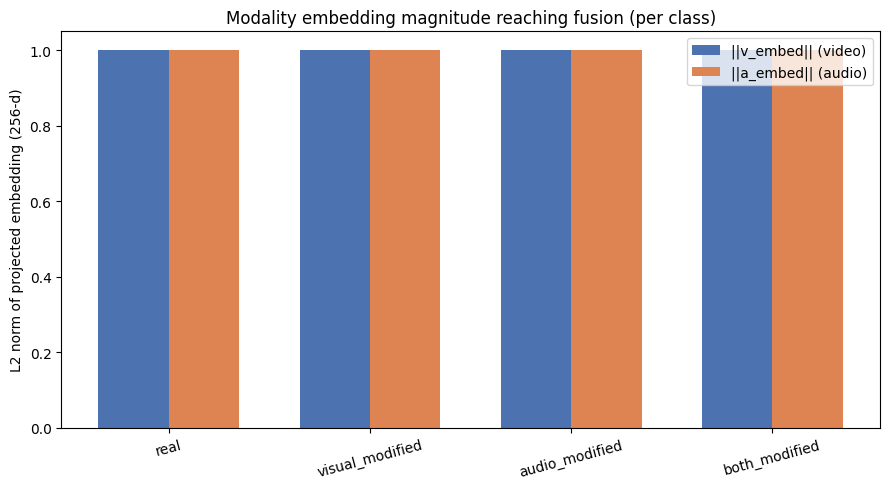


✅ Saved: lrp_fusion.png + lrp_fusion.pdf


In [37]:
# === FIXED Phase 5 — modality energy ===

def get_embeddings(model, faces_uint8, audio):
    with torch.no_grad():
        faces = faces_uint8.unsqueeze(0).to(device)
        audio_t = audio.unsqueeze(0).to(device)
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
            out = model(faces, audio_t)
        v = out.get("v_embed")
        a = out.get("a_embed")
        logits = out.get("logits_4class")
    return v, a, logits

ig_results = []
print("Computing modality energy proxy (||v_embed|| vs ||a_embed||)...")
for c in range(4):
    norms_v = []; norms_a = []
    samples_c = df_selected[df_selected["label"] == c]
    for _, row in samples_c.iterrows():
        item = torch.load(row["path"], weights_only=False)
        v, a, _ = get_embeddings(model, item["faces"], item["audio"])
        if v is not None and a is not None:
            norms_v.append(float(v.float().norm(dim=-1).mean().cpu()))
            norms_a.append(float(a.float().norm(dim=-1).mean().cpu()))
    if norms_v and norms_a:
        ig_results.append({
            "class": CLASS_NAMES[c],
            "v_norm_mean": np.mean(norms_v),
            "a_norm_mean": np.mean(norms_a),
        })
        print(f"  {CLASS_NAMES[c]:18s}  ||v_embed||={np.mean(norms_v):.3f}  ||a_embed||={np.mean(norms_a):.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
classes = [r["class"] for r in ig_results]
v_means = [r["v_norm_mean"] for r in ig_results]
a_means = [r["a_norm_mean"] for r in ig_results]
x = np.arange(len(classes))
width = 0.35
ax.bar(x - width/2, v_means, width, label="||v_embed|| (video)", color="#4C72B0")
ax.bar(x + width/2, a_means, width, label="||a_embed|| (audio)", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(classes, rotation=15)
ax.set_ylabel("L2 norm of projected embedding (256-d)")
ax.set_title("Modality embedding magnitude reaching fusion (per class)")
ax.legend()
plt.tight_layout()

out_png = RESULTS_FIGURES / "lrp_fusion.png"
out_pdf = RESULTS_FIGURES / "lrp_fusion.pdf"
plt.savefig(out_png, dpi=150, bbox_inches="tight")
plt.savefig(out_pdf, bbox_inches="tight")
plt.show()
print(f"\n✅ Saved: lrp_fusion.png + lrp_fusion.pdf")

## Phase 6 — Hero figure

The single figure that goes into the paper's lead section. Side-by-side:

| Real clip | Both-modified clip |
|---|---|
| Face crop | Face crop |
| Grad-CAM++ overlay | Grad-CAM++ overlay |
| Audio waveform | Audio waveform |
| SHAP attribution | SHAP attribution |

The contrast tells the story: real clips have diffuse saliency and quiet SHAP; manipulated
clips have concentrated saliency and sharp SHAP spikes at the synthetic segment.

C:\Users\Komal-Sch\AppData\Local\Temp\ipykernel_63672\564796645.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


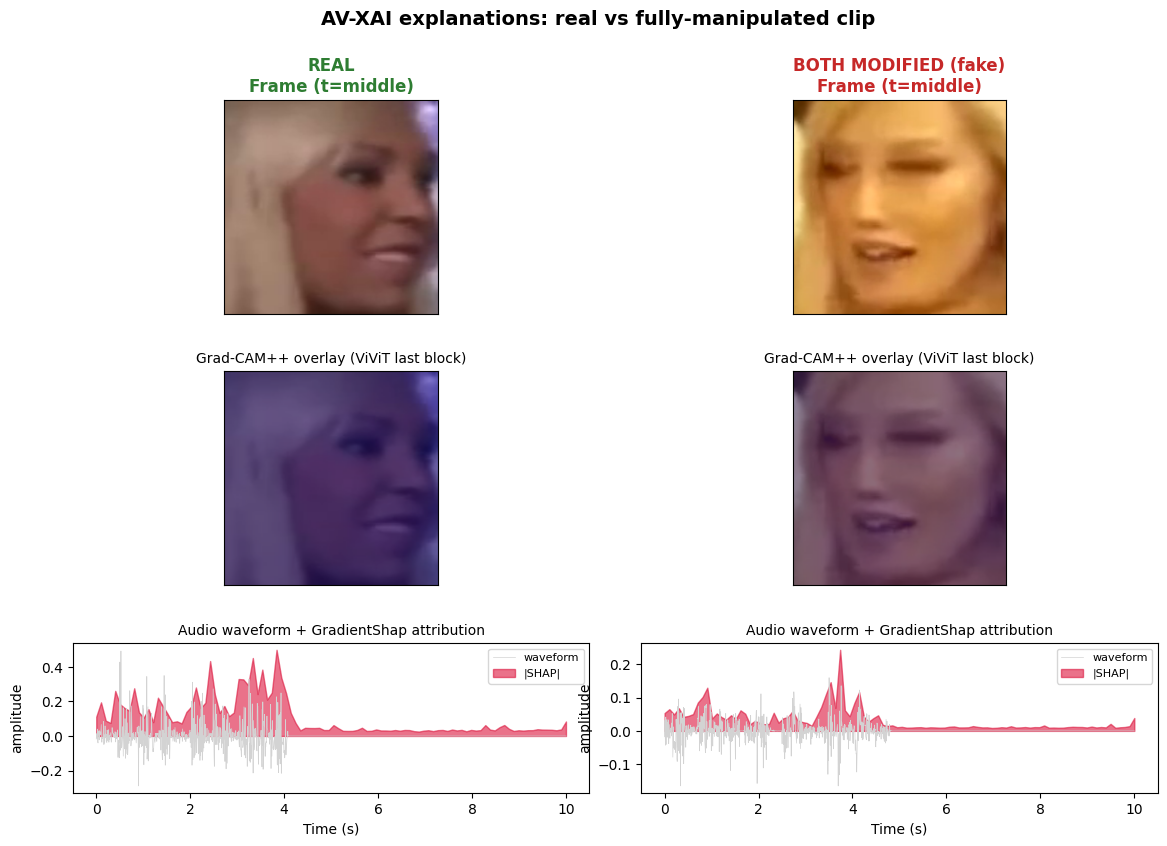


✅ Saved: hero_figure.png, hero_figure.pdf


In [38]:
# === F10: Hero figure — real vs both_modified side-by-side ===

# Pick one real and one both_modified clip from the gradcam results
hero_samples = []
for target_class in [0, 3]:  # real, both_modified
    for r in results_gcam:
        if r["label"] == target_class:
            hero_samples.append(r)
            break

# Match with their SHAP results
hero_shap = {}
for r in shap_results:
    if r["label"] in [0, 3]:
        hero_shap[r["label"]] = r

fig = plt.figure(figsize=(14, 9))
gs = gridspec.GridSpec(3, 2, height_ratios=[1, 1, 0.7], figure=fig, hspace=0.3, wspace=0.1)

for col, sample in enumerate(hero_samples):
    label = sample["label"]
    title = "REAL" if label == 0 else "BOTH MODIFIED (fake)"
    color = "#2E7D32" if label == 0 else "#C62828"

    # Row 0: original face frame
    ax_f = fig.add_subplot(gs[0, col])
    ax_f.imshow(sample["frame"])
    ax_f.set_xticks([]); ax_f.set_yticks([])
    ax_f.set_title(f"{title}\nFrame (t=middle)", fontsize=12, color=color, fontweight="bold")

    # Row 1: Grad-CAM++ overlay
    ax_g = fig.add_subplot(gs[1, col])
    ax_g.imshow(sample["overlay"])
    ax_g.set_xticks([]); ax_g.set_yticks([])
    ax_g.set_title("Grad-CAM++ overlay (ViViT last block)", fontsize=10)

    # Row 2: Audio + SHAP
    ax_a = fig.add_subplot(gs[2, col])
    if label in hero_shap:
        sh = hero_shap[label]
        wf = sh["audio"][::100]
        t_wf = np.linspace(0, 10, len(wf))
        ax_a.plot(t_wf, wf, color="lightgray", linewidth=0.5, label="waveform")
        attr_w = np.abs(sh["attr"].reshape(N_WINDOWS, WINDOW)).sum(axis=1)
        time_s = np.linspace(0, 10, N_WINDOWS)
        ax_a.fill_between(time_s, 0, attr_w / (attr_w.max() + 1e-9) * sh["audio"].max(),
                            alpha=0.6, color="crimson", label="|SHAP|")
        ax_a.set_xlabel("Time (s)", fontsize=10)
        ax_a.set_ylabel("amplitude")
        ax_a.legend(loc="upper right", fontsize=8)
        ax_a.set_title("Audio waveform + GradientShap attribution", fontsize=10)
    else:
        ax_a.text(0.5, 0.5, "SHAP unavailable", ha="center", va="center", transform=ax_a.transAxes)

fig.suptitle("AV-XAI explanations: real vs fully-manipulated clip", fontsize=14, fontweight="bold")
plt.tight_layout()

out_png = RESULTS_FIGURES / "hero_figure.png"
out_pdf = RESULTS_FIGURES / "hero_figure.pdf"
plt.savefig(out_png, dpi=180, bbox_inches="tight")
plt.savefig(out_pdf, bbox_inches="tight")
plt.show()
print(f"\n✅ Saved: {out_png.name}, {out_pdf.name}")

## Done

**Figures produced:**
- `results/figures/gradcam_grid.{png,pdf}` — F6, 8-panel Grad-CAM++ grid
- `results/figures/shap_audio.{png,pdf}` — F7, GradientShap audio attribution
- `results/figures/attention_weights.{png,pdf}` — F8, fusion attention matrices
- `results/figures/lrp_fusion.{png,pdf}` — F9, modality energy at fusion
- `results/figures/hero_figure.{png,pdf}` — F10, real vs fake hero figure

**Tables:**
- `results/tables/xai_selected_samples.csv` — the 8 clips visualized

**Commit to git (run on Windows CMD):**

```cmd
cd C:\Users\Komal-Sch\Desktop\AV-XAI
git add notebooks\07_xai_visualization.ipynb
git add -f results\figures\gradcam_grid.png results\figures\gradcam_grid.pdf
git add -f results\figures\shap_audio.png results\figures\shap_audio.pdf
git add -f results\figures\attention_weights.png results\figures\attention_weights.pdf
git add -f results\figures\lrp_fusion.png results\figures\lrp_fusion.pdf
git add -f results\figures\hero_figure.png results\figures\hero_figure.pdf
git add -f results\tables\xai_selected_samples.csv
git commit -m "nb07: XAI figures (Grad-CAM++, GradientShap, attention, IG, hero)"
git push origin main
```

**For the paper:**
- F6 (Grad-CAM grid) → §4.5 Qualitative Visual Analysis
- F7 (audio SHAP) → §4.5, key support for audio dominance finding
- F8 (attention) → §3.3 Fusion module discussion, or §4.5
- F9 (modality energy) → §4.5, complement to A1 modality ablation
- F10 (hero) → §1 Introduction or §4 opening